# Multi-Task Loss Weight (λ) Sensitivity Analysis — AST-MTDKT

Companion experiment that justifies the multi-task loss weight λ used in AST-MTDKT.

The training objective is:

`Loss = Correctness Loss + λ × Skill Loss`

λ controls how much gradient signal from the auxiliary skill-prediction task reaches the shared LSTM
encoder. Too small (λ → 0) and the skill task barely trains; too large and skill-loss gradients can
dominate the shared encoder and hurt the primary correctness task (task interference).

**Protocol** — identical to the main notebook: `MAX_PROBLEMS = 4053`, `EPOCHS = 30`, `patience = 5`,
`batch_size = 32`, `lr = 0.001`, `weight_decay = 1e-4`, and the same leakage-free 5-fold user-level
cross-validation. Candidate values: λ ∈ {0.0, 0.1, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0}.

**Runtime note.** The full 5-fold CV run is repeated once per λ (8 values), so total runtime is roughly
8× the main experiment. Reduce `LAMBDA_CANDIDATES` for a coarser, faster sweep.


In [1]:
# ==========================================================
# IMPORTS
# ==========================================================

import os
import ast
import random
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import KFold
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

from tqdm import tqdm

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


In [2]:
# ==========================================================
# CONFIG — identical to the main notebook's settings
# ==========================================================

# Set the CODENET_PATH environment variable, or replace the default below
DATASET_PATH = os.environ.get("CODENET_PATH", r"path/to/Project_CodeNet")

MAX_PROBLEMS = 4053         # same as main notebook
MIN_INTERACTIONS_PER_USER = 20

N_FOLDS = 5                 # same 5-fold user-level CV as main notebook
EPOCHS = 30                 # same as main notebook
PATIENCE = 5                # same as main notebook
BATCH_SIZE = 32             # same as main notebook
LEARNING_RATE = 0.001       # same as main notebook
WEIGHT_DECAY = 1e-4         # same as main notebook
HIDDEN_SIZE = 128           # same as main notebook

LAMBDA_CANDIDATES = [0.0, 0.1, 0.3, 0.5, 0.7, 1.0, 1.5, 2.0]

SKILLS = [
    "if_else", "loops", "functions", "recursion", "arrays_lists",
    "dictionaries", "strings", "algorithms", "basic_syntax"
]
skill_to_idx = {s: i for i, s in enumerate(SKILLS)}
num_skills = len(SKILLS)

In [3]:
# ==========================================================
# AST SKILL EXTRACTOR  (identical to main notebook)
# ==========================================================

class SkillExtractor(ast.NodeVisitor):

    def __init__(self):
        self.skills = set()
        self.current_function = None

    def visit_If(self, node):
        self.skills.add("if_else")
        self.generic_visit(node)

    def visit_For(self, node):
        self.skills.add("loops")
        self.generic_visit(node)

    def visit_While(self, node):
        self.skills.add("loops")
        self.generic_visit(node)

    def visit_FunctionDef(self, node):
        self.skills.add("functions")
        previous = self.current_function
        self.current_function = node.name
        self.generic_visit(node)
        self.current_function = previous

    def visit_Call(self, node):
        if isinstance(node.func, ast.Name):
            if node.func.id == self.current_function:
                self.skills.add("recursion")
        if isinstance(node.func, ast.Attribute):
            if node.func.attr in ["append", "pop", "extend"]:
                self.skills.add("arrays_lists")
            if node.func.attr in ["split", "strip", "replace", "join"]:
                self.skills.add("strings")
            if node.func.attr in ["sort"]:
                self.skills.add("algorithms")
        self.generic_visit(node)

    def visit_List(self, node):
        self.skills.add("arrays_lists")
        self.generic_visit(node)

    def visit_Dict(self, node):
        self.skills.add("dictionaries")
        self.generic_visit(node)

In [4]:
# ==========================================================
# LOAD FULL DATASET (MAX_PROBLEMS = 4053, same as main notebook)
# ==========================================================

metadata_path = os.path.join(DATASET_PATH, "metadata")
data_path = os.path.join(DATASET_PATH, "data")

metadata_files = [
    f for f in os.listdir(metadata_path)
    if f.endswith(".csv") and f != "problem_list.csv"
]

random.shuffle(metadata_files)
metadata_files = metadata_files[:MAX_PROBLEMS]

print(f"Problems loaded for this experiment: {len(metadata_files)}")

all_rows = []

for file_name in tqdm(metadata_files, desc="Processing problems"):
    try:
        problem_id = file_name.replace(".csv", "")
        df_temp = pd.read_csv(os.path.join(metadata_path, file_name))

        language_col = next((c for c in df_temp.columns if "language" in c.lower()), None)
        if language_col is None:
            continue

        df_temp = df_temp[df_temp[language_col].astype(str).str.contains("python", case=False, na=False)]
        if len(df_temp) == 0:
            continue

        df_temp["correct"] = (df_temp["status"] == "Accepted").astype(int)

        if "date" in df_temp.columns:
            df_temp["timestamp"] = pd.to_datetime(df_temp["date"], errors="coerce")
            df_temp["timestamp"] = df_temp["timestamp"].astype(np.int64) // 10**9
        else:
            df_temp["timestamp"] = np.arange(len(df_temp))

        for _, row in df_temp.iterrows():
            try:
                submission_id = str(row["submission_id"])
                code_file = os.path.join(data_path, problem_id, "Python", f"{submission_id}.py")
                if not os.path.exists(code_file):
                    continue

                with open(code_file, "r", encoding="utf-8", errors="ignore") as f:
                    code = f.read()

                try:
                    tree = ast.parse(code)
                    extractor = SkillExtractor()
                    extractor.visit(tree)
                    skills = list(extractor.skills)
                    if len(skills) == 0:
                        skills = ["basic_syntax"]
                except Exception:
                    skills = ["basic_syntax"]

                all_rows.append({
                    "user_id": row["user_id"],
                    "timestamp": row["timestamp"],
                    "correct": row["correct"],
                    "skills": skills
                })
            except Exception:
                continue
    except Exception:
        continue

df = pd.DataFrame(all_rows)
print(f"Interactions: {len(df):,}")

user_counts = df.groupby("user_id").size()
active_users = user_counts[user_counts >= MIN_INTERACTIONS_PER_USER].index
df = df[df["user_id"].isin(active_users)]
print(f"Students: {df['user_id'].nunique():,}")

Problems loaded for this experiment: 4053


Processing problems: 100%|██████████| 4053/4053 [1:31:14<00:00,  1.35s/it]  


Interactions: 3,286,314
Students: 19,049


In [5]:
# ==========================================================
# SEQUENCE BUILDING, DATASET, COLLATE, MODEL
# (identical logic to the main notebook)
# ==========================================================

def build_sequences(dataframe, max_seq_len=50, stride=25):
    sequences, targets, skill_targets = [], [], []
    grouped = dataframe.groupby("user_id")

    for _, group in grouped:
        group = group.sort_values("timestamp")
        interactions = []

        for _, row in group.iterrows():
            skills = row["skills"]
            correct = row["correct"]

            multi_hot = torch.zeros(2 * num_skills)
            skill_vector = torch.zeros(num_skills)

            for skill in skills:
                if skill not in skill_to_idx:
                    continue
                idx = skill_to_idx[skill]
                skill_vector[idx] = 1
                if correct == 1:
                    multi_hot[idx] = 1
                else:
                    multi_hot[num_skills + idx] = 1

            interactions.append((multi_hot, correct, skill_vector))

        if len(interactions) < 5:
            continue

        seq_x, seq_y, seq_skill = [], [], []
        for i in range(len(interactions) - 1):
            current_x, _, _ = interactions[i]
            next_correct = interactions[i + 1][1]
            next_skill = interactions[i + 1][2]
            seq_x.append(current_x)
            seq_y.append(next_correct)
            seq_skill.append(next_skill)

        for j in range(0, len(seq_x), stride):
            x_part = seq_x[j:j + max_seq_len]
            y_part = seq_y[j:j + max_seq_len]
            s_part = seq_skill[j:j + max_seq_len]

            if len(x_part) >= 5:
                sequences.append(torch.stack(x_part))
                targets.append(torch.tensor(y_part, dtype=torch.float))
                skill_targets.append(torch.stack(s_part))

    return sequences, targets, skill_targets


class DKTDataset(Dataset):
    def __init__(self, sequences, targets, skill_targets):
        self.sequences = sequences
        self.targets = targets
        self.skill_targets = skill_targets

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], self.targets[idx], self.skill_targets[idx]


def collate_fn(batch):
    sequences, targets, skill_targets = zip(*batch)
    padded_sequences = nn.utils.rnn.pad_sequence(sequences, batch_first=True)
    padded_targets = nn.utils.rnn.pad_sequence(targets, batch_first=True, padding_value=-1)
    padded_skills = nn.utils.rnn.pad_sequence(skill_targets, batch_first=True, padding_value=-1)
    return padded_sequences, padded_targets, padded_skills


class MultiTaskDKT(nn.Module):
    def __init__(self, num_skills, hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=2 * num_skills, hidden_size=hidden_size,
            num_layers=2, batch_first=True, dropout=0.3
        )
        self.dropout = nn.Dropout(0.3)
        self.correct_head = nn.Sequential(
            nn.Linear(hidden_size, hidden_size), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(hidden_size, 1)
        )
        self.skill_head = nn.Sequential(
            nn.Linear(hidden_size, hidden_size), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(hidden_size, num_skills)
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.dropout(out)
        correct_logits = self.correct_head(out)
        skill_logits = self.skill_head(out)
        return correct_logits.squeeze(-1), skill_logits

In [6]:
# ==========================================================
# EPOCH RUNNER — identical training/eval logic to the main notebook,
# but lambda is passed in rather than hardcoded.
# ==========================================================

def run_epoch(model, loader, lambda_skill, criterion_correct, criterion_skill,
              optimizer=None, train=True):

    model.train() if train else model.eval()

    total_loss = 0.0
    all_preds, all_targets = [], []
    all_skill_preds, all_skill_targets = [], []

    for seqs, targets, skill_targets in loader:
        seqs = seqs.to(device)
        targets = targets.to(device)
        skill_targets = skill_targets.to(device)
        mask = (targets != -1)

        if train:
            optimizer.zero_grad()

        with torch.set_grad_enabled(train):
            correct_logits, skill_logits = model(seqs)
            valid_logits = correct_logits[mask]
            valid_targets = targets[mask]

            loss_correct = criterion_correct(valid_logits, valid_targets)

            skill_mask = (skill_targets != -1)
            loss_skill = criterion_skill(skill_logits[skill_mask], skill_targets[skill_mask])

            loss = loss_correct + lambda_skill * loss_skill

            if train:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

        total_loss += loss.item()

        probs = torch.sigmoid(valid_logits)
        all_preds.extend(probs.detach().cpu().numpy())
        all_targets.extend(valid_targets.detach().cpu().numpy())

        skill_probs = torch.sigmoid(skill_logits[skill_mask])
        all_skill_preds.extend((skill_probs.detach().cpu().numpy() > 0.5).astype(int))
        all_skill_targets.extend(skill_targets[skill_mask].detach().cpu().numpy().astype(int))

    preds_binary = (np.array(all_preds) > 0.5).astype(int)

    acc = accuracy_score(all_targets, preds_binary)
    auc = roc_auc_score(all_targets, all_preds)
    precision = precision_score(all_targets, preds_binary, zero_division=0)
    recall = recall_score(all_targets, preds_binary, zero_division=0)
    f1 = f1_score(all_targets, preds_binary, zero_division=0)
    skill_f1 = f1_score(all_skill_targets, all_skill_preds, average="macro", zero_division=0)

    return total_loss / len(loader), acc, auc, precision, recall, f1, skill_f1

In [7]:
# ==========================================================
# TRAIN + EVALUATE ONE LAMBDA WITH FULL 5-FOLD USER-LEVEL CV
# (same protocol as the main notebook's final results)
# ==========================================================

def train_with_lambda_cv(lambda_skill, users, n_folds=N_FOLDS, epochs=EPOCHS, patience=PATIENCE):

    kf = KFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    fold_metrics = []

    for fold, (train_idx, val_idx) in enumerate(kf.split(users)):

        train_users = users[train_idx]
        val_users = users[val_idx]

        train_df = df[df["user_id"].isin(train_users)]
        val_df = df[df["user_id"].isin(val_users)]

        train_seq, train_tgt, train_skill_tgt = build_sequences(train_df)
        val_seq, val_tgt, val_skill_tgt = build_sequences(val_df)

        train_loader = DataLoader(
            DKTDataset(train_seq, train_tgt, train_skill_tgt),
            batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn
        )
        val_loader = DataLoader(
            DKTDataset(val_seq, val_tgt, val_skill_tgt),
            batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn
        )

        torch.manual_seed(SEED)
        model = MultiTaskDKT(num_skills=num_skills).to(device)
        optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        criterion_correct = nn.BCEWithLogitsLoss()
        criterion_skill = nn.BCEWithLogitsLoss()

        best_auc, best_fold_metrics, counter = 0.0, None, 0

        for epoch in range(epochs):
            run_epoch(model, train_loader, lambda_skill, criterion_correct, criterion_skill,
                      optimizer, train=True)

            val_loss, val_acc, val_auc, val_prec, val_rec, val_f1, val_skill_f1 = run_epoch(
                model, val_loader, lambda_skill, criterion_correct, criterion_skill,
                optimizer=None, train=False
            )

            if val_auc > best_auc:
                best_auc = val_auc
                best_fold_metrics = {
                    "fold": fold + 1, "epoch": epoch + 1, "val_loss": val_loss,
                    "val_acc": val_acc, "val_auc": val_auc, "val_precision": val_prec,
                    "val_recall": val_rec, "val_f1": val_f1, "val_skill_f1": val_skill_f1
                }
                counter = 0
            else:
                counter += 1
                if counter >= patience:
                    break

        fold_metrics.append(best_fold_metrics)

    fm = pd.DataFrame(fold_metrics)
    summary = {
        "lambda": lambda_skill,
        "val_auc_mean": fm["val_auc"].mean(), "val_auc_std": fm["val_auc"].std(),
        "val_acc_mean": fm["val_acc"].mean(), "val_acc_std": fm["val_acc"].std(),
        "val_f1_mean": fm["val_f1"].mean(), "val_f1_std": fm["val_f1"].std(),
        "val_precision_mean": fm["val_precision"].mean(),
        "val_recall_mean": fm["val_recall"].mean(),
        "val_skill_f1_mean": fm["val_skill_f1"].mean(), "val_skill_f1_std": fm["val_skill_f1"].std(),
    }
    return summary, fm

In [8]:
# ==========================================================
# RUN THE GRID SEARCH — full 5-fold CV per lambda value
# ==========================================================

users = df["user_id"].unique()

print("=" * 70)
print("LAMBDA SENSITIVITY ANALYSIS (5-fold CV per lambda, matching main protocol)")
print("=" * 70)

lambda_search_results = []
lambda_fold_details = {}

for lam in LAMBDA_CANDIDATES:
    print(f"\n--- lambda = {lam} ---")
    summary, fold_df = train_with_lambda_cv(lam, users)
    lambda_search_results.append(summary)
    lambda_fold_details[lam] = fold_df
    print(f"lambda={lam:<4} | AUC={summary['val_auc_mean']:.4f}±{summary['val_auc_std']:.4f} | "
          f"Acc={summary['val_acc_mean']:.4f} | F1={summary['val_f1_mean']:.4f} | "
          f"skill_F1={summary['val_skill_f1_mean']:.4f}±{summary['val_skill_f1_std']:.4f}")

lambda_results_df = pd.DataFrame(lambda_search_results).sort_values("lambda").reset_index(drop=True)
lambda_results_df

LAMBDA SENSITIVITY ANALYSIS (5-fold CV per lambda, matching main protocol)

--- lambda = 0.0 ---
lambda=0.0  | AUC=0.6775±0.0015 | Acc=0.6385 | F1=0.6849 | skill_F1=0.4060±0.0012

--- lambda = 0.1 ---
lambda=0.1  | AUC=0.6774±0.0014 | Acc=0.6383 | F1=0.6869 | skill_F1=0.8124±0.0015

--- lambda = 0.3 ---
lambda=0.3  | AUC=0.6776±0.0013 | Acc=0.6385 | F1=0.6870 | skill_F1=0.8248±0.0020

--- lambda = 0.5 ---
lambda=0.5  | AUC=0.6778±0.0014 | Acc=0.6387 | F1=0.6875 | skill_F1=0.8298±0.0014

--- lambda = 0.7 ---
lambda=0.7  | AUC=0.6777±0.0013 | Acc=0.6387 | F1=0.6883 | skill_F1=0.8308±0.0011

--- lambda = 1.0 ---
lambda=1.0  | AUC=0.6778±0.0013 | Acc=0.6388 | F1=0.6880 | skill_F1=0.8315±0.0014

--- lambda = 1.5 ---
lambda=1.5  | AUC=0.6778±0.0014 | Acc=0.6386 | F1=0.6893 | skill_F1=0.8319±0.0016

--- lambda = 2.0 ---
lambda=2.0  | AUC=0.6778±0.0013 | Acc=0.6387 | F1=0.6874 | skill_F1=0.8321±0.0018


,lambda,val_auc_mean,val_auc_std,val_acc_mean,val_acc_std,val_f1_mean,val_f1_std,val_precision_mean,val_recall_mean,val_skill_f1_mean,val_skill_f1_std
0,0.0,0.677508,0.001547,0.638456,0.001277,0.684850,0.002668,0.655680,0.716768,0.405959,0.001218
1,0.1,0.677418,0.001400,0.638316,0.001264,0.686869,0.003478,0.653581,0.723854,0.812375,0.001513
2,0.3,0.677625,0.001345,0.638467,0.001303,0.687028,0.005254,0.653689,0.724200,0.824846,0.002032
3,0.5,0.677784,0.001389,0.638695,0.001326,0.687485,0.004214,0.653600,0.725188,0.829798,0.001403
4,0.7,0.677737,0.001348,0.638682,0.001510,0.688250,0.003719,0.652860,0.727769,0.830779,0.001064
5,1.0,0.677793,0.001326,0.638782,0.001309,0.687999,0.002406,0.653255,0.726662,0.831504,0.001424
6,1.5,0.677765,0.001385,0.638567,0.001358,0.689297,0.002484,0.651736,0.731538,0.831948,0.001589
7,2.0,0.677803,0.001333,0.638715,0.001414,0.687405,0.001868,0.653721,0.724785,0.832100,0.001846


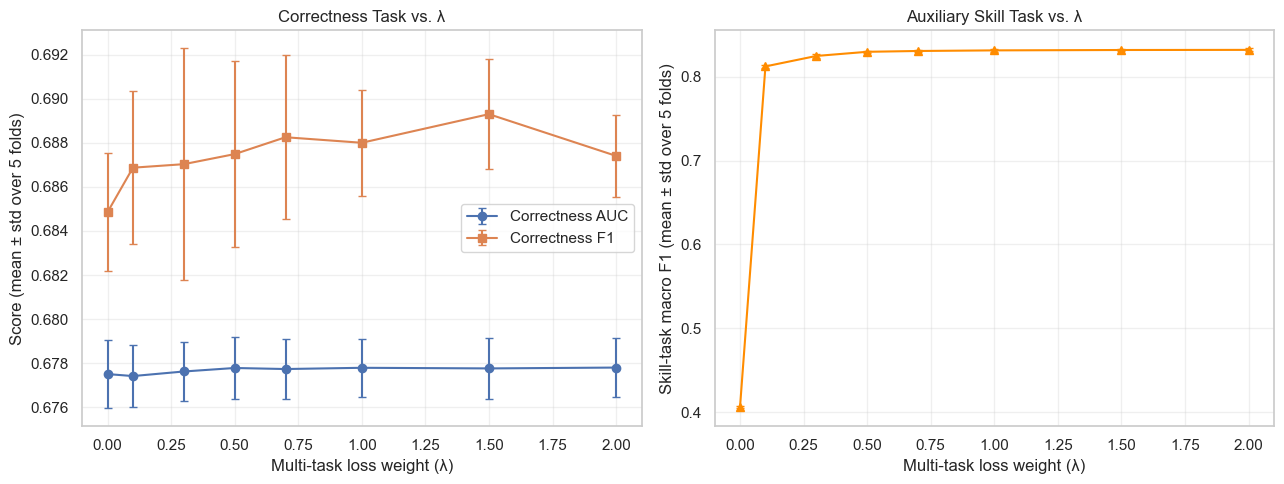


Selected lambda (max mean correctness AUC, subject to skill task not collapsing):
lambda                2.000000
val_auc_mean          0.677803
val_auc_std           0.001333
val_acc_mean          0.638715
val_acc_std           0.001414
val_f1_mean           0.687405
val_f1_std            0.001868
val_precision_mean    0.653721
val_recall_mean       0.724785
val_skill_f1_mean     0.832100
val_skill_f1_std      0.001846
Name: 7, dtype: float64

>>> BEST_LAMBDA = 2.0


In [9]:
# ==========================================================
# PLOT + SELECT BEST LAMBDA
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].errorbar(lambda_results_df["lambda"], lambda_results_df["val_auc_mean"],
                  yerr=lambda_results_df["val_auc_std"], marker="o", capsize=3, label="Correctness AUC")
axes[0].errorbar(lambda_results_df["lambda"], lambda_results_df["val_f1_mean"],
                  yerr=lambda_results_df["val_f1_std"], marker="s", capsize=3, label="Correctness F1")
axes[0].set_xlabel("Multi-task loss weight (λ)")
axes[0].set_ylabel("Score (mean ± std over 5 folds)")
axes[0].set_title("Correctness Task vs. λ")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].errorbar(lambda_results_df["lambda"], lambda_results_df["val_skill_f1_mean"],
                  yerr=lambda_results_df["val_skill_f1_std"], marker="^", capsize=3, color="darkorange")
axes[1].set_xlabel("Multi-task loss weight (λ)")
axes[1].set_ylabel("Skill-task macro F1 (mean ± std over 5 folds)")
axes[1].set_title("Auxiliary Skill Task vs. λ")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("lambda_sensitivity_analysis.png", dpi=200)
plt.show()

# Selection rule: maximize mean correctness AUC, subject to the skill task
# not collapsing (skill_f1 above 30% of its own max across the sweep).
SKILL_F1_FLOOR = 0.3 * lambda_results_df["val_skill_f1_mean"].max()
candidates = lambda_results_df[lambda_results_df["val_skill_f1_mean"] >= SKILL_F1_FLOOR]
best_row = candidates.loc[candidates["val_auc_mean"].idxmax()]

print("\nSelected lambda (max mean correctness AUC, subject to skill task not collapsing):")
print(best_row)

BEST_LAMBDA = float(best_row["lambda"])
print(f"\n>>> BEST_LAMBDA = {BEST_LAMBDA}")